# Stage 8 – Corrected DGI-GCN Graph-Based Adversarial Detection

**Research:** *An Unsupervised Graph-Based Framework for Adversarial Attack Detection and Severity Estimation in Deep Learning-Based Alzheimer’s MRI Classification.*

## Purpose
This notebook evaluates adversarial detection using the frozen Stage 6 GCN encoder and corrected Stage 7 attacks, while retaining the manuscript anomaly score and fixed threshold:

\[S_i=\|h_i-\mu\|_2,\qquad \widehat y_i=1\text{ if }S_i>0.4\text{, otherwise }0.\]

## Correction made
The previous notebook used a one-way graph extension: adversarial nodes received messages from clean neighbours, while clean nodes did not receive messages from adversarial nodes. It then compared embeddings generated under two different graph contexts. This notebook replaces that with a **symmetric augmented graph** for each split/attack:
- preserve the original Stage 5 clean-clean edges;
- connect each adversarial node to its 10 most cosine-similar clean nodes;
- add reverse edges so the augmented adjacency is symmetric;
- recompute embeddings for all clean and adversarial nodes using the frozen Stage 6 GCN;
- calculate the centroid from clean training-node embeddings in that same augmented graph.

The manuscript does not fully specify out-of-sample graph inference. Therefore, symmetric augmentation is an explicit implementation choice to be reviewed—not a claim that this detail is explicitly prescribed by the manuscript.

## Important limitations
1. Stage 5/6 used all 6,400 clean nodes in a transductive unsupervised graph-learning procedure.
2. Stage 4 CNN and Stage 6 GCN weights remain frozen; no model retraining occurs here.
3. Each split/attack is evaluated in its own augmented graph. The clean training centroid is recomputed in that same graph context.
4. Stage 7 attacks were generated only for images correctly classified by the clean CNN. Attack success rates are conditional on that subset.
5. Threshold 0.4 is fixed and not tuned on the test set. If it is incompatible with the embedding scale, the notebook reports that problem rather than silently changing it.
6. The dataset split is image-level; patient-level independence cannot be claimed.

**Do not update manuscript tables until these outputs have been reviewed.**

**Inference detail:** the symmetric augmentation is a reproducible implementation choice because the manuscript does not specify how adversarial nodes are inserted into the graph. Review this choice with the research supervisor before claiming exact methodological reproduction.

## 1. Set up the Colab environment
Run this cell first. A GPU is recommended for CNN feature extraction.

In [1]:
import os, glob, json, zipfile, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score
)
from sklearn.neighbors import NearestNeighbors

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
import scipy
print("SciPy:", scipy.__version__)
print("Device:", DEVICE)


PyTorch: 2.14.1+cu130
SciPy: 1.16.3
Device: cuda


## 2. Upload the four required ZIP files
Select all four ZIP files together. If they are already present in the Colab session, you can skip the upload dialog and set `uploaded` to the existing filenames.

In [2]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))


Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs.zip
Saving Stage5_Graph_Outputs.zip to Stage5_Graph_Outputs.zip
Saving Stage6_DGI_Outputs.zip to Stage6_DGI_Outputs.zip
Saving Stage7_Final_Corrected_Outputs.zip to Stage7_Final_Corrected_Outputs.zip
Uploaded: ['Stage4_CNN_Outputs.zip', 'Stage5_Graph_Outputs.zip', 'Stage6_DGI_Outputs.zip', 'Stage7_Final_Corrected_Outputs.zip']


## 3. Extract the ZIP files and locate the required outputs

In [3]:
WORK = Path("/content/stage8_work")
WORK.mkdir(parents=True, exist_ok=True)

def safe_extract(zip_path, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (out_dir / member.filename).resolve()
            if not str(target).startswith(str(out_dir.resolve())):
                raise ValueError("Unsafe path detected in ZIP.")
        zf.extractall(out_dir)

def uploaded_zip(keyword):
    matches = [name for name in uploaded if name.lower().endswith(".zip") and keyword.lower() in name.lower()]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one uploaded ZIP containing '{keyword}'. Found: {matches}")
    return matches[0]

ZIP_DIRS = {}
for key in ["Stage4", "Stage5", "Stage6", "Stage7"]:
    zname = uploaded_zip(key)
    dest = WORK / key.lower()
    safe_extract(zname, dest)
    ZIP_DIRS[key] = dest
    print(f"\\n{key}: {zname}")
    for p in sorted(dest.rglob("*")):
        if p.is_file():
            print(" ", p.relative_to(dest))


\nStage4: Stage4_CNN_Outputs.zip
  best_alzheimer_cnn.pth
  cnn_embedding_manifest.csv
  cnn_embeddings_128d.npz
  cnn_test_class_metrics.csv
  cnn_test_confusion_matrix.csv
  cnn_training_history.csv
  stage4_config_and_metrics.json
\nStage5: Stage5_Graph_Outputs.zip
  cosine_knn_adjacency.npz
  cosine_knn_edges_directed.csv
  graph_construction_config.json
  graph_node_features_and_masks.npz
  graph_node_manifest.csv
\nStage6: Stage6_DGI_Outputs.zip
  stage6_dgi_config.json
  stage6_dgi_gcn_model.pt
  stage6_dgi_graph_embeddings.npz
  stage6_dgi_training_history.csv
\nStage7: Stage7_Final_Corrected_Outputs.zip
  stage7_clean_classifier_summary.csv
  stage7_constraint_checks.csv
  stage7_final_attack_summary.csv
  stage7_final_config.json
  test_CW_L2_correct_only.npz
  test_FGSM_correct_only.npz
  test_PGD_correct_only.npz
  train_CW_L2_correct_only.npz
  train_FGSM_correct_only.npz
  train_PGD_correct_only.npz
  validation_CW_L2_correct_only.npz
  validation_FGSM_correct_only.npz
  

## 4. Load Stage 4 CNN embeddings and checkpoint

In [4]:
def find_one(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f"Expected one {filename} under {root}; found {len(found)}")
    return found[0]

emb_path = find_one(ZIP_DIRS["Stage4"], "cnn_embeddings_128d.npz")
cnn_ckpt_path = find_one(ZIP_DIRS["Stage4"], "best_alzheimer_cnn.pth")
with np.load(emb_path, allow_pickle=False) as z:
    emb_data = {k: z[k] for k in z.files}

required_keys = [
    "train_embeddings", "validation_embeddings", "test_embeddings",
    "train_indices", "validation_indices", "test_indices"
]
missing = [k for k in required_keys if k not in emb_data]
if missing:
    raise KeyError(f"Missing Stage 4 embedding keys: {missing}")

idx_train = emb_data["train_indices"].astype(np.int64)
idx_val = emb_data["validation_indices"].astype(np.int64)
idx_test = emb_data["test_indices"].astype(np.int64)

N = len(idx_train) + len(idx_val) + len(idx_test)
X_clean = np.zeros((N, 128), dtype=np.float32)
X_clean[idx_train] = emb_data["train_embeddings"].astype(np.float32)
X_clean[idx_val] = emb_data["validation_embeddings"].astype(np.float32)
X_clean[idx_test] = emb_data["test_embeddings"].astype(np.float32)

assert N == 6400 and X_clean.shape == (6400, 128)
assert len(np.unique(np.concatenate([idx_train, idx_val, idx_test]))) == N
assert np.isfinite(X_clean).all()
print("Clean CNN feature matrix:", X_clean.shape)
print("Split counts:", len(idx_train), len(idx_val), len(idx_test))

class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, embedding_dim=128, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2)
        )
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.embedding = nn.Linear(256, embedding_dim)
        self.embedding_activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
    def forward(self, x, return_embedding=False):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        z = self.embedding_activation(self.embedding(x))
        logits = self.classifier(self.dropout(z))
        return (logits, z) if return_embedding else logits

cnn_checkpoint = torch.load(cnn_ckpt_path, map_location=DEVICE, weights_only=False)
class_names = cnn_checkpoint.get("class_names", ["Mild Demented", "Moderate Demented", "Non-Demented", "Very Mild Demented"])
cnn = AlzheimerCNN(num_classes=len(class_names)).to(DEVICE)
cnn.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn.eval()
print("Loaded Stage 4 CNN checkpoint from epoch:", cnn_checkpoint.get("epoch"))


Clean CNN feature matrix: (6400, 128)
Split counts: 4480 960 960
Loaded Stage 4 CNN checkpoint from epoch: 49


## 5. Load the Stage 5 graph and recreate the GCN normalization

In [5]:
adj_path = find_one(ZIP_DIRS["Stage5"], "cosine_knn_adjacency.npz")
A = sp.load_npz(adj_path).tocsr().astype(np.float32)
assert A.shape == (N, N)
assert (A - A.T).nnz == 0
assert np.all(A.data >= 0) and np.isfinite(A.data).all()

A_hat = (A + sp.eye(N, dtype=np.float32, format="csr")).tocsr()
degree = np.asarray(A_hat.sum(axis=1)).ravel().astype(np.float32)
d_inv_sqrt = np.power(degree, -0.5)
D_inv_sqrt = sp.diags(d_inv_sqrt)
A_norm = (D_inv_sqrt @ A_hat @ D_inv_sqrt).tocsr().astype(np.float32)

def scipy_to_torch_sparse(matrix, device):
    coo = matrix.tocoo()
    indices = torch.tensor(np.vstack([coo.row, coo.col]), dtype=torch.long, device=device)
    values = torch.tensor(coo.data, dtype=torch.float32, device=device)
    return torch.sparse_coo_tensor(indices, values, coo.shape, device=device).coalesce()

A_torch = scipy_to_torch_sparse(A_norm, DEVICE)
X_torch = torch.tensor(X_clean, dtype=torch.float32, device=DEVICE)
print("Graph:", A.shape, "| undirected edges:", A.nnz // 2)
print("Degree range with self-loops:", float(degree.min()), float(degree.max()))


Graph: (6400, 6400) | undirected edges: 43681
Degree range with self-loops: 10.409370422363281 30.994962692260742


/tmp/ipykernel_1397/2714831749.py:17: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, coo.shape, device=device).coalesce()


## 6. Load the frozen Stage 6 GCN-DGI encoder and verify clean embeddings

In [6]:
class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features, out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
    def forward(self, x, adj):
        support = torch.matmul(x, self.weight)
        out = torch.sparse.mm(adj, support)
        if self.bias is not None:
            out = out + self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.gc1 = GraphConvolution(in_dim, hidden_dim)
        self.gc2 = GraphConvolution(hidden_dim, hidden_dim)
        self.dropout = dropout
    def forward(self, x, adj):
        h = F.relu(self.gc1(x, adj))
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.gc2(h, adj)

gcn_path = find_one(ZIP_DIRS["Stage6"], "stage6_dgi_gcn_model.pt")
dgi_path = find_one(ZIP_DIRS["Stage6"], "stage6_dgi_graph_embeddings.npz")
gcn = GCNEncoder().to(DEVICE)
dgi_state = torch.load(gcn_path, map_location=DEVICE, weights_only=True)
# Stage 6 saved the full DGI model; extract only the encoder parameters.
encoder_state = {k.replace("encoder.", "", 1): v for k, v in dgi_state.items() if k.startswith("encoder.")}
if not encoder_state:
    raise KeyError("No encoder.* parameters found in the Stage 6 DGI checkpoint.")
gcn.load_state_dict(encoder_state, strict=True)
gcn.eval()

with np.load(dgi_path, allow_pickle=False) as z:
    H_stage6 = z["graph_embeddings"].astype(np.float32)
    stage6_train_idx = z["train_indices"].astype(np.int64)
    stage6_val_idx = z["val_indices"].astype(np.int64)
    stage6_test_idx = z["test_indices"].astype(np.int64)

assert H_stage6.shape == (N, 128)
assert np.array_equal(idx_train, stage6_train_idx)
assert np.array_equal(idx_val, stage6_val_idx)
assert np.array_equal(idx_test, stage6_test_idx)

with torch.no_grad():
    H_recomputed = gcn(X_torch, A_torch).cpu().numpy()

max_abs_diff = float(np.max(np.abs(H_recomputed - H_stage6)))
print("Maximum absolute difference from saved Stage 6 graph embeddings:", max_abs_diff)
assert max_abs_diff < 1e-4, "Recomputed embeddings do not match Stage 6. Stop and share this output."
print("Stage 6 encoder and graph embeddings verified.")


Maximum absolute difference from saved Stage 6 graph embeddings: 5.960464477539062e-07
Stage 6 encoder and graph embeddings verified.


## 7. Calculate the clean training centroid and inspect the manuscript threshold

The centroid is fitted only on clean training graph embeddings:

\[
\mu=\frac{1}{N_{\mathrm{train}}}\sum_{i\in\mathrm{train}}h_i
\]

The manuscript threshold is kept at 0.4 for this first evaluation. This cell checks whether that value is compatible with the actual Stage 6 embedding scale.


In [7]:
TAU_MANUSCRIPT = 0.4
mu_clean_train = H_stage6[idx_train].mean(axis=0)
clean_train_scores = np.linalg.norm(H_stage6[idx_train] - mu_clean_train, axis=1)
clean_val_scores = np.linalg.norm(H_stage6[idx_val] - mu_clean_train, axis=1)
clean_test_scores = np.linalg.norm(H_stage6[idx_test] - mu_clean_train, axis=1)

def describe_scores(values, name):
    q = np.quantile(values, [0, .05, .25, .50, .75, .90, .95, .99, 1])
    print(name, "n=", len(values), "mean=", round(float(np.mean(values)), 5))
    print("  min, p05, p25, median, p75, p90, p95, p99, max:", np.round(q, 5))
    print("  fraction above manuscript tau=0.4:", round(float(np.mean(values > TAU_MANUSCRIPT)), 5))

describe_scores(clean_train_scores, "Clean train")
describe_scores(clean_val_scores, "Clean validation")
describe_scores(clean_test_scores, "Clean test")

threshold_diagnostic = pd.DataFrame([
    {"split":"train_clean", "n":len(clean_train_scores), "mean_score":clean_train_scores.mean(),
     "median_score":np.median(clean_train_scores), "p95_score":np.quantile(clean_train_scores,.95),
     "fraction_flagged_at_0.4":np.mean(clean_train_scores > TAU_MANUSCRIPT)},
    {"split":"validation_clean", "n":len(clean_val_scores), "mean_score":clean_val_scores.mean(),
     "median_score":np.median(clean_val_scores), "p95_score":np.quantile(clean_val_scores,.95),
     "fraction_flagged_at_0.4":np.mean(clean_val_scores > TAU_MANUSCRIPT)},
    {"split":"test_clean", "n":len(clean_test_scores), "mean_score":clean_test_scores.mean(),
     "median_score":np.median(clean_test_scores), "p95_score":np.quantile(clean_test_scores,.95),
     "fraction_flagged_at_0.4":np.mean(clean_test_scores > TAU_MANUSCRIPT)}
])
display(threshold_diagnostic)


Clean train n= 4480 mean= 1.86115
  min, p05, p25, median, p75, p90, p95, p99, max: [0.9702  1.14976 1.29572 1.55959 2.2745  2.93377 3.37554 4.22672 5.8853 ]
  fraction above manuscript tau=0.4: 1.0
Clean validation n= 960 mean= 1.84663
  min, p05, p25, median, p75, p90, p95, p99, max: [0.98152 1.12312 1.29499 1.5726  2.17549 2.90736 3.4662  4.38306 5.16383]
  fraction above manuscript tau=0.4: 1.0
Clean test n= 960 mean= 1.80353
  min, p05, p25, median, p75, p90, p95, p99, max: [0.96474 1.11487 1.27714 1.53486 2.14487 2.8626  3.31748 3.94239 6.30969]
  fraction above manuscript tau=0.4: 1.0


,split,n,mean_score,median_score,p95_score,fraction_flagged_at_0.4
0,train_clean,4480,1.861155,1.559586,3.375544,1.0
1,validation_clean,960,1.846630,1.572602,3.466197,1.0
2,test_clean,960,1.803529,1.534857,3.317476,1.0


## 8. Define symmetric augmented-graph inference

For each split/attack evaluation, retain the original clean graph and attach adversarial nodes to their 10 nearest clean nodes using cosine similarity. Add both directions of every new edge, then recompute all node embeddings with the frozen GCN. This ensures paired clean and adversarial samples are represented under the same augmented adjacency.

In [8]:
K_NEIGHBORS = 10
TAU_MANUSCRIPT = 0.4

X_unit = X_clean / np.maximum(np.linalg.norm(X_clean, axis=1, keepdims=True), 1e-12)
knn = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(X_unit)

def normalize_augmented_adjacency(A):
    A_hat = (A + sp.eye(A.shape[0], dtype=np.float32, format="csr")).tocsr()
    deg = np.asarray(A_hat.sum(axis=1)).ravel().astype(np.float32)
    inv = np.power(deg, -0.5)
    return (sp.diags(inv) @ A_hat @ sp.diags(inv)).tocsr().astype(np.float32)

def build_symmetric_augmented_graph(adv_features):
    adv_features = np.asarray(adv_features, dtype=np.float32)
    if adv_features.ndim != 2 or adv_features.shape[1] != 128:
        raise ValueError(f"Expected [n,128] adversarial features; got {adv_features.shape}")
    if len(adv_features) == 0 or not np.isfinite(adv_features).all():
        raise ValueError("Adversarial features are empty or contain non-finite values.")
    adv_unit = adv_features / np.maximum(np.linalg.norm(adv_features, axis=1, keepdims=True), 1e-12)
    distances, neighbor_ids = knn.kneighbors(adv_unit)
    similarities = np.clip(1.0 - distances, 0.0, 1.0).astype(np.float32)
    m = len(adv_features)
    rows, cols, vals = [], [], []
    for j in range(m):
        new_id = N + j
        for q in range(K_NEIGHBORS):
            old_id = int(neighbor_ids[j, q]); weight = float(similarities[j, q])
            if weight > 0:
                rows.extend([new_id, old_id]); cols.extend([old_id, new_id]); vals.extend([weight, weight])
    B = sp.coo_matrix((vals, (rows, cols)), shape=(N + m, N + m), dtype=np.float32).tocsr()
    A_base = sp.block_diag((A, sp.csr_matrix((m, m), dtype=np.float32)), format="csr")
    A_aug = (A_base + B).tocsr()
    A_aug = A_aug.maximum(A_aug.T).tocsr()
    A_aug.setdiag(0); A_aug.eliminate_zeros()
    if (A_aug - A_aug.T).nnz != 0:
        raise AssertionError("Augmented graph is not symmetric.")
    return A_aug

def compute_augmented_embeddings(adv_features):
    A_aug = build_symmetric_augmented_graph(adv_features)
    X_aug = np.vstack([X_clean, np.asarray(adv_features, dtype=np.float32)])
    A_aug_norm = normalize_augmented_adjacency(A_aug)
    A_aug_t = scipy_to_torch_sparse(A_aug_norm, DEVICE)
    X_aug_t = torch.tensor(X_aug, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        H_aug = gcn(X_aug_t, A_aug_t).cpu().numpy().astype(np.float32)
    if not np.isfinite(H_aug).all():
        raise ValueError("Non-finite embeddings in augmented graph.")
    return H_aug, A_aug

print("Symmetric augmented-graph inference ready; k =", K_NEIGHBORS, "| fixed threshold =", TAU_MANUSCRIPT)

Symmetric augmented-graph inference ready; k = 10 | fixed threshold = 0.4


## 9. Load the Stage 7 corrected attack arrays and extract adversarial CNN embeddings
The Stage 7 ZIP must contain `train_FGSM_correct_only.npz`, `validation_FGSM_correct_only.npz`, etc. This stage checks each file's indices, labels and attack-success flags.

In [9]:
ATTACK_NAMES = ["FGSM", "PGD", "CW_L2"]
SPLIT_NAMES = ["train", "validation", "test"]
attack_records = []

for split in SPLIT_NAMES:
    for attack in ATTACK_NAMES:
        fname = f"{split}_{attack}_correct_only.npz"
        p = find_one(ZIP_DIRS["Stage7"], fname)
        with np.load(p, allow_pickle=False) as z:
            rec = {k: z[k] for k in z.files}
        required = ["indices", "adversarial_images", "labels", "clean_predictions",
                    "adversarial_predictions", "attack_success"]
        missing = [k for k in required if k not in rec]
        if missing:
            raise KeyError(f"{fname} missing keys: {missing}")
        n = len(rec["indices"])
        assert rec["adversarial_images"].shape == (n,1,128,128)
        assert np.isfinite(rec["adversarial_images"]).all()
        assert rec["adversarial_images"].min() >= -1e-6 and rec["adversarial_images"].max() <= 1+1e-6
        assert np.array_equal(rec["attack_success"], rec["adversarial_predictions"] != rec["labels"])
        expected_split = {"train":idx_train, "validation":idx_val, "test":idx_test}[split]
        assert np.isin(rec["indices"], expected_split).all(), f"{fname}: indices outside {split} split"
        assert len(np.unique(rec["indices"])) == n, f"{fname}: duplicate indices"
        attack_records.append((split, attack, rec, p))
        print(split, attack, "| n =", n, "| successful =", int(rec["attack_success"].sum()))


train FGSM | n = 4303 | successful = 4301
train PGD | n = 4303 | successful = 4303
train CW_L2 | n = 4303 | successful = 4303
validation FGSM | n = 798 | successful = 797
validation PGD | n = 798 | successful = 797
validation CW_L2 | n = 798 | successful = 798
test FGSM | n = 793 | successful = 793
test PGD | n = 793 | successful = 793
test CW_L2 | n = 793 | successful = 793


## 10. Extract Stage 4 CNN embeddings for the adversarial images

In [10]:
def extract_cnn_embeddings(images, batch_size=64):
    images = np.asarray(images, dtype=np.float32)
    outputs = []
    cnn.eval()
    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            xb = torch.tensor(images[start:start+batch_size], dtype=torch.float32, device=DEVICE)
            logits, z = cnn(xb, return_embedding=True)
            outputs.append(z.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs, axis=0) if outputs else np.empty((0,128), dtype=np.float32)

# For each split/attack, infer clean and adversarial nodes together in one symmetric graph.
for split, attack, rec, path in attack_records:
    t0 = time.time()
    rec["adversarial_cnn_embeddings"] = extract_cnn_embeddings(rec["adversarial_images"])
    H_aug, A_aug = compute_augmented_embeddings(rec["adversarial_cnn_embeddings"])
    rec["augmented_clean_embeddings"] = H_aug[:N]
    rec["adversarial_graph_embeddings"] = H_aug[N:]
    # Centroid is formed only from clean training nodes, within this same augmented graph.
    rec["clean_training_centroid"] = H_aug[idx_train].mean(axis=0)
    rec["augmented_graph_undirected_edges"] = int(A_aug.nnz // 2)
    assert rec["adversarial_graph_embeddings"].shape == (len(rec["indices"]), 128)
    print(split, attack, "embeddings:", rec["adversarial_graph_embeddings"].shape,
          "| augmented edges:", rec["augmented_graph_undirected_edges"],
          "| elapsed min:", round((time.time()-t0)/60, 2))

train FGSM embeddings: (4303, 128) | augmented edges: 86711 | elapsed min: 0.04
train PGD embeddings: (4303, 128) | augmented edges: 86711 | elapsed min: 0.02
train CW_L2 embeddings: (4303, 128) | augmented edges: 86711 | elapsed min: 0.02
validation FGSM embeddings: (798, 128) | augmented edges: 51661 | elapsed min: 0.0
validation PGD embeddings: (798, 128) | augmented edges: 51661 | elapsed min: 0.0
validation CW_L2 embeddings: (798, 128) | augmented edges: 51661 | elapsed min: 0.0
test FGSM embeddings: (793, 128) | augmented edges: 51611 | elapsed min: 0.0
test PGD embeddings: (793, 128) | augmented edges: 51611 | elapsed min: 0.0
test CW_L2 embeddings: (793, 128) | augmented edges: 51611 | elapsed min: 0.0


## 11. Calculate clean and adversarial anomaly scores

For each split/attack, both the paired clean node and its adversarial counterpart are scored against the clean-training centroid from the **same augmented graph**. The score remains the manuscript's Euclidean distance.

In [11]:
all_score_rows = []
for split, attack, rec, path in attack_records:
    ids = rec["indices"].astype(np.int64)
    mu = rec["clean_training_centroid"]
    H_clean_pair = rec["augmented_clean_embeddings"][ids]
    H_adv = rec["adversarial_graph_embeddings"]
    clean_scores = np.linalg.norm(H_clean_pair - mu[None, :], axis=1)
    adv_scores = np.linalg.norm(H_adv - mu[None, :], axis=1)
    rec["clean_paired_scores"] = clean_scores
    rec["adversarial_scores"] = adv_scores

    for j, node_id in enumerate(ids):
        all_score_rows.append({
            "split": split, "attack": attack, "node_index": int(node_id),
            "sample_type": "clean_paired", "true_detection_label": 0,
            "attack_success": False, "anomaly_score": float(clean_scores[j]),
            "predicted_adversarial_tau_0_4": bool(clean_scores[j] > TAU_MANUSCRIPT)
        })
        all_score_rows.append({
            "split": split, "attack": attack, "node_index": int(node_id),
            "sample_type": "adversarial", "true_detection_label": int(rec["attack_success"][j]),
            "attack_success": bool(rec["attack_success"][j]), "anomaly_score": float(adv_scores[j]),
            "predicted_adversarial_tau_0_4": bool(adv_scores[j] > TAU_MANUSCRIPT)
        })

scores_df = pd.DataFrame(all_score_rows)
display(scores_df.head(10))
print("Score rows:", len(scores_df))

,split,attack,node_index,sample_type,true_detection_label,attack_success,anomaly_score,predicted_adversarial_tau_0_4
0,train,FGSM,64,clean_paired,0,False,1.570824,True
1,train,FGSM,64,adversarial,1,True,3.450512,True
2,train,FGSM,67,clean_paired,0,False,2.947227,True
3,train,FGSM,67,adversarial,1,True,3.312651,True
4,train,FGSM,68,clean_paired,0,False,1.874122,True
5,train,FGSM,68,adversarial,1,True,4.872336,True
6,train,FGSM,69,clean_paired,0,False,1.330846,True
7,train,FGSM,69,adversarial,1,True,4.684809,True
8,train,FGSM,70,clean_paired,0,False,1.398081,True
9,train,FGSM,70,adversarial,1,True,3.787508,True


Score rows: 35364


## 12. Evaluate detection on validation and test splits
Successful attacks are positive examples. Their paired clean images are negative examples. Failed attack attempts are not counted as positive adversarial examples.

In [12]:
metric_rows = []
for split in ["validation", "test"]:
    for attack in ATTACK_NAMES:
        sub = scores_df[(scores_df["split"]==split) & (scores_df["attack"]==attack)]
        clean = sub[sub["sample_type"]=="clean_paired"]
        adv = sub[(sub["sample_type"]=="adversarial") & (sub["attack_success"]==True)]
        if len(adv)==0:
            print("No successful adversarial examples:", split, attack)
            continue
        eval_df = pd.concat([clean, adv], ignore_index=True)
        y_true = eval_df["true_detection_label"].to_numpy(dtype=int)
        y_pred = eval_df["predicted_adversarial_tau_0_4"].to_numpy(dtype=int)
        metric_rows.append({
            "split":split, "attack":attack, "threshold":TAU_MANUSCRIPT,
            "clean_negative_samples":len(clean), "successful_adversarial_positive_samples":len(adv),
            "TN":int(((y_true==0)&(y_pred==0)).sum()),
            "FP":int(((y_true==0)&(y_pred==1)).sum()),
            "FN":int(((y_true==1)&(y_pred==0)).sum()),
            "TP":int(((y_true==1)&(y_pred==1)).sum()),
            "precision":precision_score(y_true,y_pred,zero_division=0),
            "recall":recall_score(y_true,y_pred,zero_division=0),
            "f1":f1_score(y_true,y_pred,zero_division=0),
            "accuracy":accuracy_score(y_true,y_pred)
        })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)


,split,attack,threshold,clean_negative_samples,successful_adversarial_positive_samples,TN,FP,FN,TP,precision,recall,f1,accuracy
0,validation,FGSM,0.4,798,797,0,798,0,797,0.499687,1.0,0.666388,0.499687
1,validation,PGD,0.4,798,797,0,798,0,797,0.499687,1.0,0.666388,0.499687
2,validation,CW_L2,0.4,798,798,0,798,0,798,0.500000,1.0,0.666667,0.500000
3,test,FGSM,0.4,793,793,0,793,0,793,0.500000,1.0,0.666667,0.500000
4,test,PGD,0.4,793,793,0,793,0,793,0.500000,1.0,0.666667,0.500000
5,test,CW_L2,0.4,793,793,0,793,0,793,0.500000,1.0,0.666667,0.500000


## 13. Inspect score distributions and threshold behaviour
These plots are diagnostic. Do not select a new threshold using the test labels. A validation-based threshold-calibration experiment can be conducted separately after reviewing these results.

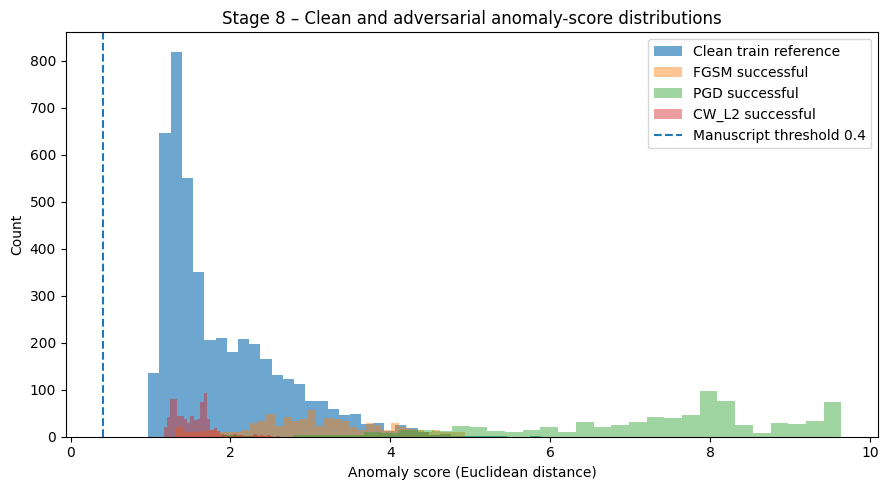

,split,attack,threshold,precision,recall,f1,false_positive_rate
0,validation,FGSM,0.4,0.499687,1.000000,0.666388,1.000000
1,validation,PGD,0.4,0.499687,1.000000,0.666388,1.000000
2,validation,CW_L2,0.4,0.500000,1.000000,0.666667,1.000000
6,validation,FGSM,0.6,0.499687,1.000000,0.666388,1.000000
7,validation,PGD,0.6,0.499687,1.000000,0.666388,1.000000
8,validation,CW_L2,0.6,0.500000,1.000000,0.666667,1.000000
12,validation,FGSM,0.8,0.499687,1.000000,0.666388,1.000000
13,validation,PGD,0.8,0.499687,1.000000,0.666388,1.000000
14,validation,CW_L2,0.8,0.500000,1.000000,0.666667,1.000000
18,validation,FGSM,1.0,0.499687,1.000000,0.666388,1.000000


In [13]:
# Clean training reference and paired clean/attack scores on the test split.
plt.figure(figsize=(9,5))
plt.hist(clean_train_scores, bins=35, alpha=0.65, label="Clean train reference")
for attack in ATTACK_NAMES:
    vals = scores_df[(scores_df.split=="test") & (scores_df.attack==attack) &
                     (scores_df.sample_type=="adversarial") & (scores_df.attack_success==True)]["anomaly_score"].to_numpy()
    if len(vals):
        plt.hist(vals, bins=35, alpha=0.45, label=f"{attack} successful")
plt.axvline(TAU_MANUSCRIPT, linestyle="--", label="Manuscript threshold 0.4")
plt.xlabel("Anomaly score (Euclidean distance)")
plt.ylabel("Count")
plt.title("Stage 8 – Clean and adversarial anomaly-score distributions")
plt.legend()
plt.tight_layout()
plt.show()

threshold_rows = []
for tau in [0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]:
    # This is a descriptive sensitivity table, not a test-set threshold-selection procedure.
    for split in ["validation", "test"]:
        for attack in ATTACK_NAMES:
            sub = scores_df[(scores_df.split==split) & (scores_df.attack==attack)]
            clean = sub[sub.sample_type=="clean_paired"]
            adv = sub[(sub.sample_type=="adversarial") & (sub.attack_success==True)]
            if len(adv)==0: continue
            eval_df = pd.concat([clean,adv],ignore_index=True)
            yt = eval_df.true_detection_label.to_numpy(dtype=int)
            yp = (eval_df.anomaly_score.to_numpy() > tau).astype(int)
            threshold_rows.append({
                "split":split,"attack":attack,"threshold":tau,
                "precision":precision_score(yt,yp,zero_division=0),
                "recall":recall_score(yt,yp,zero_division=0),
                "f1":f1_score(yt,yp,zero_division=0),
                "false_positive_rate":float(np.mean(yp[yt==0])) if np.any(yt==0) else np.nan
            })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df[threshold_df.split=="validation"])


## 14. Save Stage 8 outputs

In [14]:
OUT = Path("/content/Stage8_Corrected_Outputs")
OUT.mkdir(parents=True, exist_ok=True)

scores_df.to_csv(OUT/"stage8_anomaly_scores.csv", index=False)
metrics_df.to_csv(OUT/"stage8_detection_metrics_tau_0.4.csv", index=False)
threshold_diagnostic.to_csv(OUT/"stage8_clean_threshold_diagnostic.csv", index=False)
threshold_df.to_csv(OUT/"stage8_threshold_sensitivity_diagnostic.csv", index=False)

config = {
    "stage": 8,
    "method": "DGI-GCN graph embedding centroid-distance anomaly detection",
    "anomaly_score": "Euclidean distance between graph embedding and clean training centroid",
    "centroid_source": "clean training-node embeddings recomputed in the same split/attack augmented graph",
    "manuscript_threshold": float(TAU_MANUSCRIPT),
    "threshold_selection": "fixed manuscript value 0.4; not tuned on test labels",
    "cnn_checkpoint": "Stage 4 best_alzheimer_cnn.pth (frozen)",
    "gcn_checkpoint": "Stage 6 stage6_dgi_gcn_model.pt (frozen)",
    "adversarial_feature_extraction": "Stage 4 CNN embeddings from Stage 7 adversarial images",
    "adversarial_graph_embedding": "symmetric augmented graph: retain clean-clean edges and add bidirectional adversarial-to-clean cosine-kNN edges; recompute all embeddings with frozen GCN",
    "knn_k": int(K_NEIGHBORS),
    "augmented_graph_inference": "symmetric bidirectional edges; clean and adversarial embeddings recomputed together",
    "methodological_note": "Adversarial-node graph inference is not fully specified in the manuscript; this is an explicit implementation choice requiring review.",
    "stage7_attack_success_flag_used_as_detection_positive": True,
    "failed_attack_attempts_counted_as_positive": False,
    "graph_protocol": "Stage 5/6 transductive clean graph; each split/attack evaluated in its own symmetric augmented graph",
    "seed": SEED,
    "device": str(DEVICE),
    "clean_embedding_reconstruction_max_abs_difference": max_abs_diff
}
with open(OUT/"stage8_config.json","w") as f:
    json.dump(config,f,indent=2)

zip_path = "/content/Stage8_Corrected_Outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(p,arcname=p.name)

print("Created:", zip_path)
print("Output files:", [p.name for p in OUT.iterdir()])
files.download(zip_path)


Created: /content/Stage8_Corrected_Outputs.zip
Output files: ['stage8_config.json', 'stage8_detection_metrics_tau_0.4.csv', 'stage8_threshold_sensitivity_diagnostic.csv', 'stage8_anomaly_scores.csv', 'stage8_clean_threshold_diagnostic.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. What to upload back for validation

After the notebook finishes, upload `Stage8_Corrected_Outputs.zip` here.

I will check:
- Whether the Stage 6 graph embeddings were reconstructed correctly.
- Whether all Stage 7 splits and attack arrays were loaded with the right indices.
- Whether adversarial embeddings are finite and 128-dimensional.
- Whether the clean centroid uses training nodes only.
- Whether the manuscript threshold 0.4 produces sensible clean false-positive behaviour.
- Whether detection metrics are computed only on successful attack examples and their paired clean samples.

**Important:** Do not update manuscript tables with expected or previously stated detection scores. Use only the results produced by this run. If the 0.4 threshold is incompatible with the measured embedding scale, we will document and resolve that before final evaluation.
